# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Finn McLachlan, Thomas Sinclair, Tarra Sai Sridhar, Bagus Kurniawan**

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster import hierarchy
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"axes.titleweight": "bold", "legend.frameon": False})   # one clean style for all figures

In [2]:
# Load data: each level file has one row per monitoring series and one column per day
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

We have been asked by the Scottish Government to give insights into river water levels in Scotland, using the daily minimum, average and maximum level of 392 monitoring series from October 2014 to October 2026. We answer two questions:

1. **Clustering:** can the stations be grouped by how their water levels behave? Each station is described by five features (variability, speed of response, rare peaks, seasonality and within-day movement) and grouped with k-means, checked against hierarchical clustering.
2. **Classification:** can we predict whether a river station will flood tomorrow from its water levels over the previous seven days? We compare a logistic regression baseline with a decision tree and a random forest.

**Main conclusions.** The stations form four groups: coastal (tidal) gauges and three river types, with fast-reacting rivers mostly in the west and slow rivers with rare peaks mostly in the east. For flood prediction the simplest model, a logistic regression, works best: on the test period it catches about a third of floods and about 1 in 5 of its warnings is correct. Water levels show that a river is already high, but not that heavy rain is coming, so floods that start from a normal level are hard to predict.

# Exploratory Data Analysis and Feature Engineering

## Loading and combining the data

The data come as three wide files (daily minimum, average and maximum level, one row per monitoring series and one column per day) and a file with each station's location. We check that the three files list the same series in the same order, then reshape them into one long table, `df_main`, with one row per series per day. Rows with no readings are dropped and the dates are converted from text.

In [3]:
# The three files should hold identical stations and dates, so they can be merged row by row.
# First check all three tables have the same number of rows and columns (stops with an error if not)
assert df_min.shape == df_avg.shape == df_max.shape
assert (df_min["Observation_ID"] == df_avg["Observation_ID"]).all() and (df_max["Observation_ID"] == df_avg["Observation_ID"]).all()
print(f"{df_avg.shape[0]} monitoring series, {df_avg.shape[1] - 3} days "
      f"({df_avg.columns[3]} to {df_avg.columns[-1]})")

392 monitoring series, 4379 days (05/10/2014 to 08/10/2026)


In [4]:
# Reshape each wide file (one column per day) into a long table (one row per series per day) and join them
ids = ["County", "Station_Name", "Observation_ID"]
long = {name: df.melt(id_vars=ids, var_name="Date", value_name=name)
        for name, df in [("Min_Level", df_min), ("Max_Level", df_max), ("Avg_Level", df_avg)]}
df_main = (long["Min_Level"].merge(long["Max_Level"], on=ids + ["Date"])
           .merge(long["Avg_Level"], on=ids + ["Date"]))

# Drop days where all three readings are missing, and turn the date text into real dates
df_main = df_main.dropna(subset=["Min_Level", "Max_Level", "Avg_Level"], how="all")
df_main["Date"] = pd.to_datetime(df_main["Date"], dayfirst=True, errors="coerce")
df_main = df_main.dropna(subset=["Date"]).copy()

In [5]:
# Smallest and largest raw readings: values such as 999999.999 are clearly error codes
df_main[["Avg_Level", "Min_Level", "Max_Level"]].agg(["min", "median", "max"]).T.round(3)

,min,median,max
Avg_Level,-190475.436,0.477,999999.999
Min_Level,-999999.999,0.430,999999.999
Max_Level,-29.638,0.540,999999.999


The raw data contain impossible values such as 999,999.999 m and −190,475 m. These are error codes and are removed below.

## Finding the coastal stations

The brief says that some sites have a tidal and a non-tidal series. Coastal gauges measure the sea, which moves with the tides rather than with rain, so they need to be identified early. Searching the IDs for the word "tidal" finds 12 series, but each of these has a partner series at the same site. The function below checks how closely each pair moves together (correlation); if the partner moves with the tide, it measures the sea too.

In [6]:
def find_coastal_series(df_wide):
    """Identify coastal (sea-level) monitoring series."""
    levels = df_wide.set_index("Observation_ID").iloc[:, 2:]
    levels = levels.where(levels.abs() < 100)

    rows = []
    for tid in [o for o in levels.index if "tidal-level" in o]:
        site = tid.split("__")[1].replace("-tidal-level", "")
        partner = [o for o in levels.index if o.split("__")[1] == site][0]
        rows.append({"site": site, "tidal_series": tid, "partner": partner,
                     "correlation": levels.loc[tid].corr(levels.loc[partner])})
    pairs = pd.DataFrame(rows)

    # Both members of every pair count as coastal
    coastal_ids = set(pairs["tidal_series"]) | set(pairs["partner"])
    return coastal_ids, pairs

# Run the check on the wide average-level file
coastal_ids, tidal_pairs = find_coastal_series(df_avg)

# Flag each series: 1 = coastal (tidal or its sea-level partner), 0 = river
obs_lookup = df_main[["Observation_ID"]].drop_duplicates()
obs_lookup["is_tidal"] = obs_lookup["Observation_ID"].isin(coastal_ids).astype(int)
df_main = df_main.drop(columns="is_tidal", errors="ignore").merge(obs_lookup, on="Observation_ID", how="left")

print(f"{len(coastal_ids)} coastal series flagged")
print(f"Correlation with the partner series: {tidal_pairs.correlation.min():.3f} to {tidal_pairs.correlation.max():.3f}")

24 coastal series flagged
Correlation with the partner series: 0.967 to 0.999


All 12 tidal series move almost exactly with their partner (correlation 0.97–0.999), so 24 series measure the sea rather than a river. They are flagged as coastal (`is_tidal = 1`). We keep them in the clustering, where they are a useful check, but leave them out of the flood classification.

## Cleaning impossible readings

A first idea was to remove every reading outside ±20 m, but each gauge measures height above its own zero point, so a "normal" level differs between stations. Figure 1 shows the typical (median) level of each series.

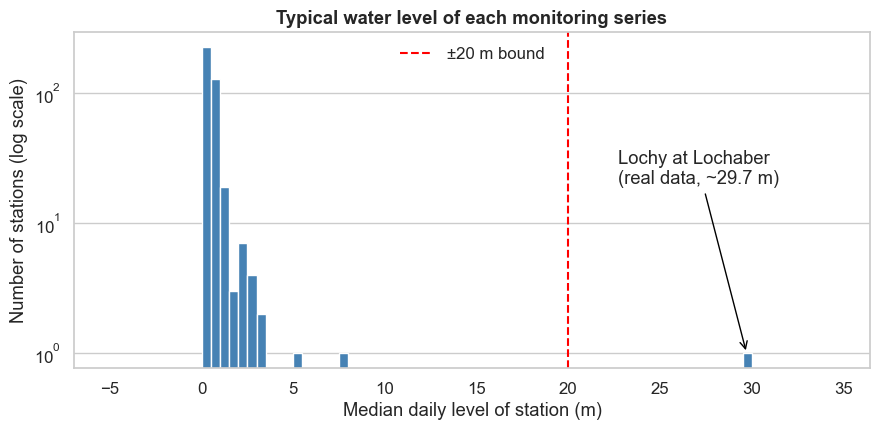

In [7]:
# Typical (median) level of each station. Levels are measured from each gauge's own zero point,
# so normal levels differ a lot between stations, and one national bound can't separate errors from real data.
station_median = df_main.groupby("Observation_ID")["Avg_Level"].median()

# Histogram of the 392 typical levels (log scale on the y-axis so single stations are still visible)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(station_median, bins=np.arange(-5, 35, 0.5), color="steelblue", edgecolor="white", log=True)
ax.axvline(20, ls="--", color="red", lw=1.5, label="±20 m bound")
lochy = station_median["inverness__lochy-lochaber__obs1"]
ax.annotate("Lochy at Lochaber\n(real data, ~29.7 m)", xy=(lochy, 1), xytext=(lochy - 7, 20),
            arrowprops=dict(arrowstyle="->", color="black", lw=1))
ax.set(xlabel="Median daily level of station (m)", ylabel="Number of stations (log scale)",
       title="Typical water level of each monitoring series")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center")
plt.tight_layout(); plt.show()

Figure 1 shows that most stations have a typical level between 0 and 3 m, but Lochy at Lochaber sits at about 29.7 m every day because its gauge has a different zero point, so a ±20 m limit would delete almost all of its real data. Instead, each reading is compared with its own station's normal range: it is removed only if it is more than 20 IQRs below the 25th or above the 75th percentile of that station. The value 20 is deliberately generous, since a real flood raises a river by a few metres while an error code is thousands of metres off; the IQR is set to at least 5 cm so that very flat stations keep their normal readings.

In [8]:
def remove_station_outliers(df, columns, k=20, min_iqr=0.05):
    """Set readings to NaN when they lie far outside their own station's typical range."""
    df = df.copy()
    n_removed = {}          # number of readings removed from each column
    for c in columns:
        grp = df.groupby("Observation_ID")[c]
        q1 = grp.transform(lambda s: s.quantile(0.25))
        q3 = grp.transform(lambda s: s.quantile(0.75))
        iqr = (q3 - q1).clip(lower=min_iqr)
        outlier = (df[c] < q1 - k * iqr) | (df[c] > q3 + k * iqr)
        n_removed[c] = int(outlier.sum())
        df.loc[outlier, c] = np.nan
    return df, n_removed

# The three level columns to clean
levels = ["Avg_Level", "Min_Level", "Max_Level"]
df_main, n_removed = remove_station_outliers(df_main, levels, k=20)
print("Readings set to missing:", n_removed)

# Daily range, computed after cleaning so error codes don't create impossible ranges
df_main["Range_Level"] = df_main["Max_Level"] - df_main["Min_Level"]
print(f"Highest level after cleaning: {df_main['Max_Level'].max():.2f} m, largest daily range: {df_main['Range_Level'].max():.2f} m")

Readings set to missing: {'Avg_Level': 208, 'Min_Level': 213, 'Max_Level': 200}
Highest level after cleaning: 34.39 m, largest daily range: 12.00 m


About 200 readings per level were removed (under 0.02% of the data), including all error codes; the largest daily range fell from 38 m to 12 m. Real flood peaks were kept: historic floods such as the 1993 Perth flood raised levels by a few metres, well within this tolerance (see References).

## Seasonal behaviour

To see how seasonal each station is, we take its average level in each calendar month and subtract the station's overall mean. Subtracting each station's own mean removes the zero-point problem, so all 392 series can be compared on one plot (Figure 2).

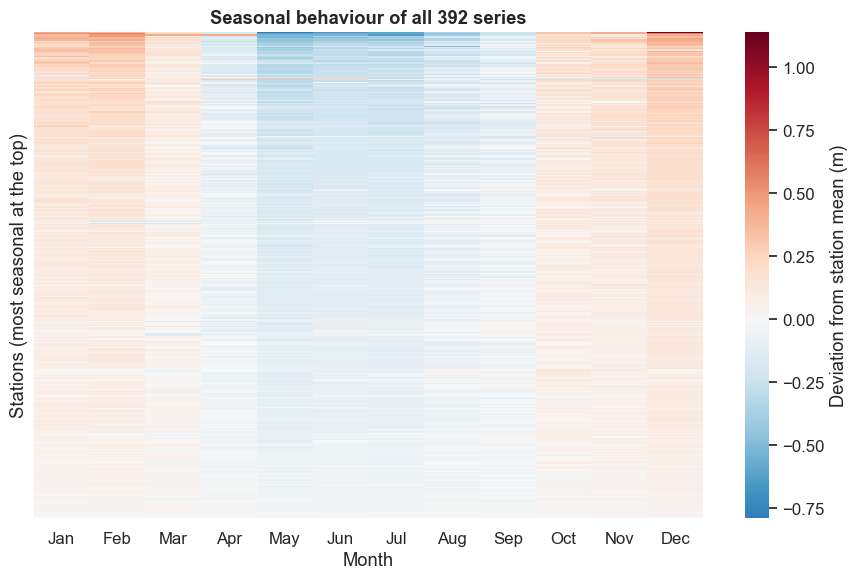

In [9]:
# Average level of every station in each calendar month (rows = stations, columns = months)
monthly_avg = (df_main.assign(month=df_main["Date"].dt.month)
               .groupby(["Observation_ID", "month"])["Avg_Level"].mean().unstack())

# Deviation of each month from the station's own mean, so stations with different zero points are comparable
row_norm = monthly_avg.sub(monthly_avg.mean(axis=1), axis=0)

# Seasonal amplitude = wettest month minus driest month (also used as a clustering feature)
seasonal_amp = monthly_avg.max(axis=1) - monthly_avg.min(axis=1)
row_norm = row_norm.loc[seasonal_amp.sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(row_norm, cmap="RdBu_r", center=0, yticklabels=False,
            xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
            cbar_kws={"label": "Deviation from station mean (m)"}, ax=ax)
ax.set(xlabel="Month", ylabel="Stations (most seasonal at the top)", title="Seasonal behaviour of all 392 series")
plt.tight_layout(); plt.show()

Figure 2 shows that almost every station is above its average in winter (red, roughly October–February) and below it in summer (blue, roughly May–August). How strong this cycle is varies a lot between stations, which is why seasonality is one of our clustering features.

## Station features for clustering

The clustering groups stations, not days, so each series is summarised by one row of features describing how its water level behaves.

A first version used the mean level, standard deviation, daily range, seasonal amplitude, number of readings and the tidal flag. We changed this because the mean level depends on the gauge's zero point, the number of readings says how long a gauge has recorded rather than how the river behaves, and the tidal flag would give part of the answer away. The seasonal amplitude in that version was also all zeros because of an index mismatch, which `fillna(0)` hid.

In [10]:
def make_station_features(df, seasonal_amp, df_locs):
    """Summarise each monitoring series into one row of behaviour features for clustering."""
    df = df.sort_values(["Observation_ID", "Date"])
    stn = df["Observation_ID"]           # used to group everything by station

    # Day-to-day change in average level, only between consecutive calendar days
    consecutive = df.groupby(stn)["Date"].diff().dt.days.eq(1)
    day_change = df.groupby(stn)["Avg_Level"].diff().where(consecutive)

    # Average levels grouped by station
    lvl = df.groupby(stn)["Avg_Level"]
    spread = lvl.quantile(0.95) - lvl.quantile(0.05)

    # One row per station, five behaviour features
    features = pd.DataFrame({
        "log_spread":  np.log(spread),
        "flashiness":  day_change.abs().groupby(stn).mean() / lvl.std(),
        "skewness":    lvl.skew(),
        "seasonality": seasonal_amp / spread,
        "daily_swing": df.groupby(stn)["Range_Level"].median() / spread,
    })

    # Descriptive information, used only to interpret the clusters (not as clustering features)
    meta = (df.groupby(stn)[["County", "Station_Name", "is_tidal"]].first()
            .join(df_locs.set_index("Observation_ID")[["Latitude", "Longitude"]])
            .assign(n_obs=lvl.count()))

    # Division by zero gives infinity; turn it into missing so those stations can be found
    features = features.replace([np.inf, -np.inf], np.nan)
    dropped = features.index[features.isna().any(axis=1)]
    print(f"Dropping {len(dropped)} stations with undefined features: {list(dropped)}")
    return features.dropna().join(meta), spread

# Build one row of features per station
station, spread = make_station_features(df_main, seasonal_amp, df_locs)

# Reduce the influence of a few extreme stations before scaling:
# cap skewness at its 1st/99th percentiles, and log-transform the very right-skewed daily swing
station["skewness"] = station["skewness"].clip(*station["skewness"].quantile([0.01, 0.99]))
station["log_daily_swing"] = np.log10(station["daily_swing"] + 0.01)

# The five columns the clustering uses
feature_cols = ["log_spread", "flashiness", "skewness", "seasonality", "log_daily_swing"]

# Standardise so every feature contributes equally to the distances (Workshop 1; Workshop 3, Ex 7)
X = StandardScaler().fit_transform(station[feature_cols])

Dropping 0 stations with undefined features: []


The five features are:

- **log_spread:** log of the range between the 5th and 95th percentile of the daily level (how much the level varies).
- **flashiness:** average day-to-day change divided by the standard deviation (fast or slow response to rain).
- **skewness:** asymmetry of the levels (rare, sharp peaks give a strong right skew).
- **seasonality:** summer–winter difference in monthly mean level divided by the spread.
- **log_daily_swing:** log10 of the median within-day range divided by the spread (high for tidal gauges).

All five are built from differences, spreads or ratios, so they do not depend on the gauge's zero point. Skewness is capped at its 1st and 99th percentiles and daily swing is log-transformed, so that a few extreme stations do not dominate. The features are then standardised so that each counts equally in the distances (Workshop 3).

## Flood classification data

For the supervised task we predict whether a river station will flood tomorrow from its water levels over the previous seven days. The steps below are designed so that no information from the future leaks into the model:

- **Coastal series** are left out, as they follow the tides, not rainfall (368 river series remain).
- **Split by date:** training up to the end of 2023, validation 2024, test 2025 to October 2026. Each row belongs to the split of the day being predicted. A random split would let the model see days next to the test days.
- **Flood definition:** tomorrow's maximum level is above the station's own 99th percentile of maximum levels, computed from the training years only. A single level for all of Scotland would not work because gauges have different zero points.
- **Scaling:** each station is scaled to itself, (level − training median) / training IQR, so 0 is a typical day.
- **Features:** the minimum, average and maximum level on each of the last seven days (21 features). Missing days are kept as gaps, so a window never joins days that are not consecutive; rows with missing values are removed.
- **Short records:** 25 stations with less than a year of training data are dropped, as their flood level would rest on a few months.

In [11]:
# Extra libraries for the classification part
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Only river series are used for the flood question (the 24 coastal series are driven by tides, not rainfall)
df_river = df_main[df_main["is_tidal"] == 0].copy()
print(f"{df_river['Observation_ID'].nunique()} river series, {len(df_river):,} daily rows")

# Date split: train up to the end of 2023, validate on 2024, test on 2025 to October 2026
TRAIN_END = pd.Timestamp("2023-12-31")
VAL_END = pd.Timestamp("2024-12-31")

# One table per level (days down, stations across) on a complete daily calendar,
# so a missing day stays missing and can't be skipped over when we look back seven days
all_days = pd.date_range(df_river["Date"].min(), df_river["Date"].max(), freq="D")
wide = {c: df_river.pivot(index="Date", columns="Observation_ID", values=c).reindex(all_days)
        for c in levels}
in_train = wide["Max_Level"].index <= TRAIN_END

# Everything the model needs to know about a station comes from the training years only
train_days = wide["Max_Level"][in_train].count()
too_short = train_days[train_days < 365].index
print(f"Dropping {len(too_short)} stations with less than a year of training data "
      f"(the first reading is in 2023 or later)")
for c in levels:
    wide[c] = wide[c].drop(columns=too_short)
in_train = wide["Max_Level"].index <= TRAIN_END

# Flood = the day's maximum level is above the station's own 99th percentile of training maximums
flood_level = wide["Max_Level"][in_train].quantile(0.99)

# Scale each station to itself: (level - training median) / training IQR.
# IQR is kept above 0.05 m (same floor as the cleaning step) so very flat stations don't blow up
scaled = {}
for c in levels:
    train_c = wide[c][in_train]
    iqr = (train_c.quantile(0.75) - train_c.quantile(0.25)).clip(lower=0.05)
    scaled[c] = (wide[c] - train_c.median()) / iqr

# 7-day features: average, minimum and maximum level on each of the last 7 days (3 x 7 = 21).
# lag0 is today, lag6 is six days ago
n_lags = 7
feature_cols_clf = [f"{c.split('_')[0]}_lag{k}" for c in levels for k in range(n_lags)]
features_clf = pd.concat(
    {f"{c.split('_')[0]}_lag{k}": scaled[c].shift(k).stack(future_stack=True)
     for c in levels for k in range(n_lags)}, axis=1)

# Target: is tomorrow's maximum level above the station's flood level?
tomorrow = wide["Max_Level"].shift(-1)
target = (tomorrow > flood_level).astype(float).where(tomorrow.notna()).stack(future_stack=True)

# Put features and target together, and drop any row with a missing value
data = features_clf.assign(flood_tomorrow=target).dropna().reset_index()
data = data.rename(columns={"level_0": "Date", "level_1": "Observation_ID"})
data["Target_Date"] = data["Date"] + pd.Timedelta(days=1)
data["flood_tomorrow"] = data["flood_tomorrow"].astype(int)

# Assign each row to a split using the day being predicted
train = data[data["Target_Date"] <= TRAIN_END]
val = data[(data["Target_Date"] > TRAIN_END) & (data["Target_Date"] <= VAL_END)]
test = data[data["Target_Date"] > VAL_END]

# Features (X) and labels (y) for each split
X_train, y_train = train[feature_cols_clf], train["flood_tomorrow"]
X_val, y_val = val[feature_cols_clf], val["flood_tomorrow"]
X_test, y_test = test[feature_cols_clf], test["flood_tomorrow"]

# Size of each split and how many flood days it has
split_summary = pd.DataFrame({
    "stations": [s["Observation_ID"].nunique() for s in (train, val, test)],
    "rows": [len(s) for s in (train, val, test)],
    "flood_days": [int(s["flood_tomorrow"].sum()) for s in (train, val, test)],
    "flood_rate_%": [100 * s["flood_tomorrow"].mean() for s in (train, val, test)],
}, index=["Train (to 2023)", "Validation (2024)", "Test (2025 - Oct 2026)"])
split_summary.round(2)

368 river series, 1,110,129 daily rows
Dropping 25 stations with less than a year of training data (the first reading is in 2023 or later)


,stations,rows,flood_days,flood_rate_%
Train (to 2023),343,739918,7504,1.01
Validation (2024),331,119112,1544,1.30
Test (2025 - Oct 2026),332,201491,1746,0.87


By construction, about 1% of training days are floods (7,504). The validation year has more (1.30%) and the test period fewer (0.87%), but both still contain enough flood days (1,544 and 1,746) for a meaningful evaluation. Slightly fewer stations appear in the later splits because some stopped recording.

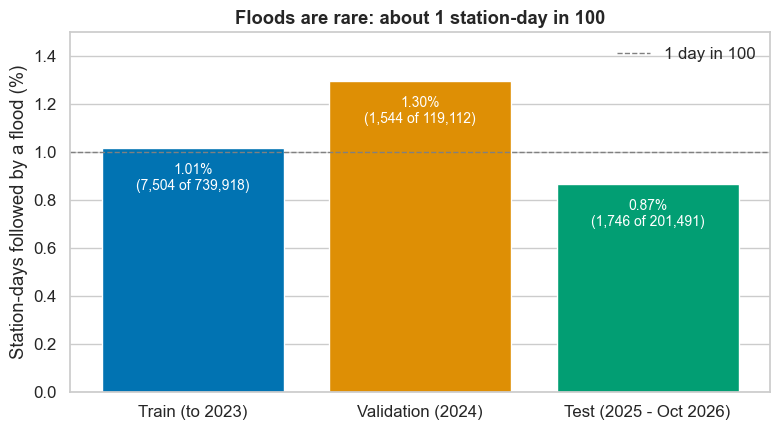

In [12]:
# One figure: how rare are flood days in each split?
fig, ax = plt.subplots(figsize=(8, 4.5))
rate = split_summary["flood_rate_%"]
bars = ax.bar(rate.index, rate.values, color=sns.color_palette("colorblind")[:3])
for bar, (n_flood, n_rows) in zip(bars, zip(split_summary["flood_days"], split_summary["rows"])):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 0.06,
            f"{bar.get_height():.2f}%\n({n_flood:,} of {n_rows:,})", ha="center", va="top", color="white", fontsize=10)
ax.axhline(1, color="grey", ls="--", lw=1, label="1 day in 100")
ax.set(ylabel="Station-days followed by a flood (%)", ylim=(0, 1.5),
       title="Floods are rare: about 1 station-day in 100")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Figure 3 shows that floods are rare in all three splits, at roughly one station-day in 100. This has two consequences for the modelling. Firstly, accuracy is not a useful measure: a model that always predicts "no flood" would be about 99% accurate while never finding a flood, so we use precision (how many predicted floods were real), recall (how many real floods were found) and F1 instead. Secondly, the model has to be told that floods matter more than normal days, otherwise it will mostly predict "no flood".

# Model Fitting and Tuning

## Clustering

The mean silhouette score alone is not enough to choose the number of clusters k: it is highest at k = 2, but that split is just coast versus river, which we already know. Following Workshop 3, we therefore compare k-means (k-means++ initialisation) for k = 2 to 8 using the elbow plot, the silhouette of every station, agreement with Ward hierarchical clustering, and stability when k-means is refitted on random 80% samples of the stations.

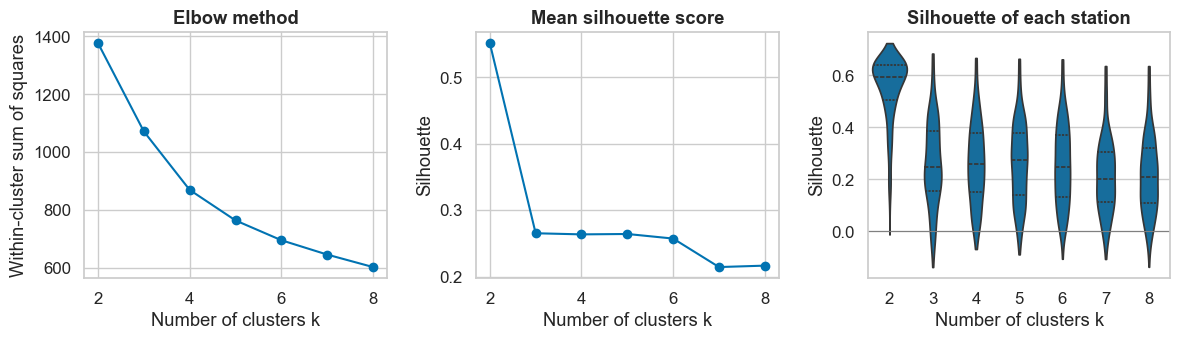

In [13]:
# Adapted from Workshop 3: k-means++ (Ex 3), elbow plot (Ex 5), silhouette analysis (Ex 6)
# Try every number of clusters from 2 to 8
K_range = range(2, 9)
km_labels, rows = {}, []
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=0).fit(X)
    km_labels[k] = km.labels_
    rows.append({"k": k, "inertia": km.inertia_, "silhouette_kmeans": silhouette_score(X, km.labels_)})
k_table = pd.DataFrame(rows).set_index("k")    # one row per k

# Silhouette of every station for each k, to show how the scores are spread, not just the mean
sil_long = pd.concat([pd.DataFrame({"k": k, "silhouette": silhouette_samples(X, km_labels[k])})
                      for k in K_range])

# Three plots side by side (Figure 4)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
k_table["inertia"].plot(ax=axes[0], marker="o")
axes[0].set(title="Elbow method", ylabel="Within-cluster sum of squares")
k_table["silhouette_kmeans"].plot(ax=axes[1], marker="o")
axes[1].set(title="Mean silhouette score", ylabel="Silhouette")
sns.violinplot(data=sil_long, x="k", y="silhouette", ax=axes[2], cut=0, inner="quartile")
axes[2].axhline(0, color="grey", lw=0.8)
axes[2].set(title="Silhouette of each station", ylabel="Silhouette")
for ax in axes:
    ax.set_xlabel("Number of clusters k")
plt.tight_layout(); plt.show()

**Observation:** Figure 4 shows the elbow curve, the mean silhouette score and the silhouette of every station for k = 2 to 8. The mean silhouette is by far the highest at k = 2 (0.55), but drops to about 0.26 for k = 3–6 and falls further for k = 7–8. The elbow curve bends at around k = 4. The violin plots show that at k = 2 almost every station is well placed (silhouette above 0), while from k = 3 onwards a small number of stations fall below 0, meaning they lie between clusters.


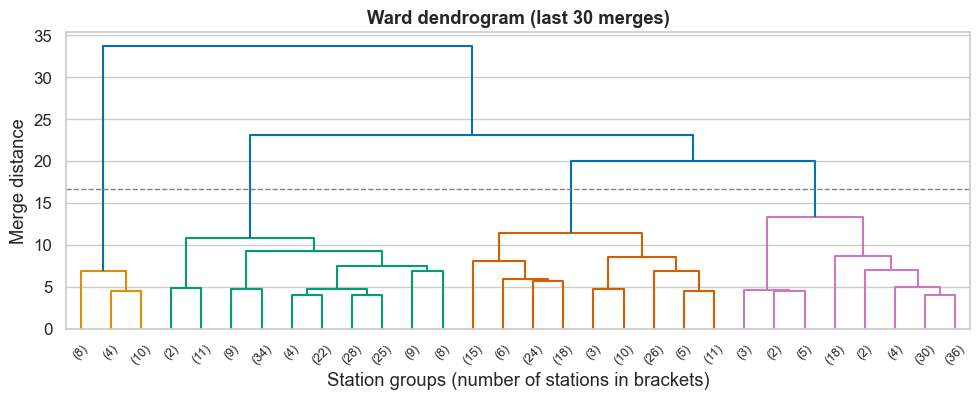

is_tidal         0   1
cluster (k=2)         
0              368   0
1                0  24


,silhouette_kmeans,silhouette_ward,ARI_kmeans_vs_ward,stability_kmeans
k,,,,
2,0.551,0.557,0.948,0.873
3,0.265,0.209,0.449,0.873
4,0.263,0.232,0.690,0.909
5,0.264,0.227,0.623,0.849
6,0.257,0.215,0.653,0.774
7,0.214,0.231,0.438,0.610
8,0.216,0.187,0.402,0.642


In [14]:
# Adapted from Workshop 3 (Ex 8-9): Ward hierarchical clustering and dendrogram
# Ward linkage: repeatedly merge the two groups whose merge adds the least within-group variance
Z = hierarchy.linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(10, 4.2))
cut = (Z[-4, 2] + Z[-3, 2]) / 2
hierarchy.dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=cut, leaf_font_size=9)
ax.axhline(cut, color="grey", ls="--", lw=1)
ax.set(title="Ward dendrogram (last 30 merges)",
       xlabel="Station groups (number of stations in brackets)", ylabel="Merge distance")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

# For each k: Ward silhouette, how much KMeans and Ward agree, and how stable KMeans is
# when refitted on random 80% subsamples (adjusted Rand index (ARI): 1 = identical clusters, 0 = chance)
rng = np.random.default_rng(0)
for k in K_range:
    ward = hierarchy.fcluster(Z, t=k, criterion="maxclust")
    k_table.loc[k, "silhouette_ward"] = silhouette_score(X, ward)
    k_table.loc[k, "ARI_kmeans_vs_ward"] = adjusted_rand_score(km_labels[k], ward)
    aris = []
    for b in range(20):
        idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
        sub = KMeans(n_clusters=k, n_init=10, random_state=b).fit_predict(X[idx])
        aris.append(adjusted_rand_score(km_labels[k][idx], sub))
    k_table.loc[k, "stability_kmeans"] = np.mean(aris)

# Check what the k = 2 split is: coastal vs river?
print(pd.crosstab(km_labels[2], station["is_tidal"], rownames=["cluster (k=2)"], colnames=["is_tidal"]))
k_table.drop(columns="inertia").round(3)   # inertia is shown in Figure 4

**Observation:** The cross-tabulation shows that k = 2 separates exactly the 24 coastal series from the 368 river series, even though the coastal flag was not used, so the features capture real differences in behaviour. For k = 3 to 6 the mean silhouette is almost constant (about 0.26), so it cannot choose k on its own. k = 4 gives the most stable clusters (ARI = 0.91 on 80% subsamples) and good agreement with Ward. The Ward dendrogram (Figure 5) shows the same structure: after the coastal stations split off, the rivers form three groups before the merge distances drop sharply; cutting at the dashed line gives these four groups.

We therefore choose **k-means with k = 4**: one coastal and three river groups. The moderate silhouette (0.26) shows that the river groups overlap, which is expected because river behaviour changes gradually.

,n_stations,n_coastal,spread_m,flashiness,skewness,seasonality,log_daily_swing
cluster,,,,,,,
0,116,0,0.96,0.27,1.36,0.51,-1.21
1,147,0,0.62,0.40,1.46,0.44,-1.03
2,105,0,0.38,0.24,2.13,0.52,-1.26
3,24,24,1.00,0.53,0.29,0.24,0.41


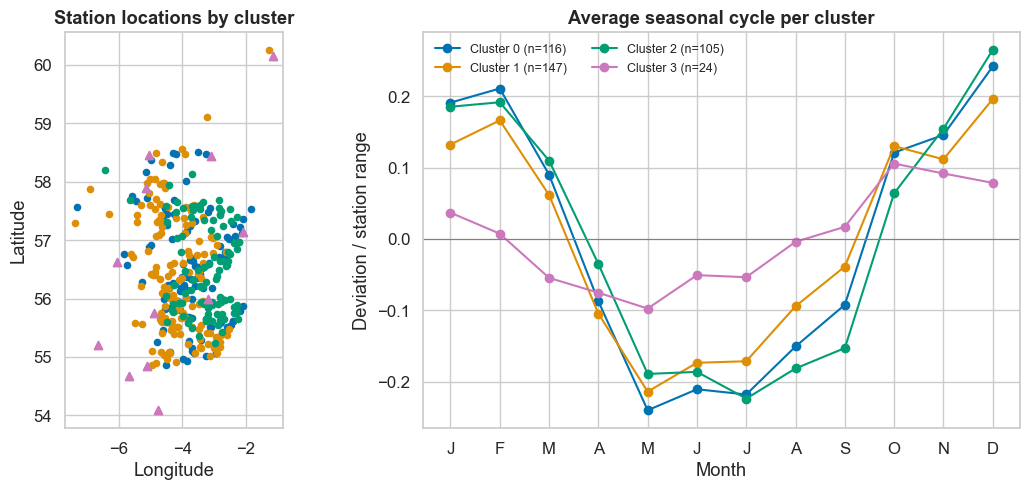

In [15]:
K = 4              # chosen above: elbow, highest stability, best agreement with Ward
METHOD = "kmeans"  # switch to "ward" to use the hierarchical clusters instead
labels = km_labels[K] if METHOD == "kmeans" else hierarchy.fcluster(Z, t=K, criterion="maxclust") - 1
station["cluster"] = labels

# Table: number of stations, number of coastal ones and the median of each feature per cluster
summary = station.groupby("cluster").agg(
    n_stations=("cluster", "size"), n_coastal=("is_tidal", "sum"),
    **{c: (c, "median") for c in feature_cols})
summary.insert(2, "spread_m", np.exp(summary.pop("log_spread")))
display(summary.round(2))

# Distinct colours for each cluster (purple for the coastal cluster, so it isn't confused with orange)
palette = [sns.color_palette("colorblind")[i] for i in (0, 1, 2, 4)]
markers = ["o", "o", "o", "^"]  # triangles for the coastal gauges

# Two panels (Figure 6): map on the left, seasonal cycle on the right
fig, (ax_map, ax_season) = plt.subplots(1, 2, figsize=(11, 5.1), gridspec_kw={"width_ratios": [1, 1.4]})
for c in range(K):
    s = station[station["cluster"] == c]
    ax_map.scatter(s["Longitude"], s["Latitude"], s=34 if c == 3 else 20, marker=markers[c],
                   color=palette[c])
ax_map.set_aspect(1 / np.cos(np.deg2rad(57)))
ax_map.set(xlabel="Longitude", ylabel="Latitude", title="Station locations by cluster")

# Right: seasonal cycle as a fraction of each station's own range, so stations are comparable
season = row_norm.loc[station.index].div(spread.loc[station.index], axis=0)
for c in range(K):
    ax_season.plot(range(1, 13), season[station["cluster"] == c].mean().values, marker="o", color=palette[c],
                   label=f"Cluster {c} (n={(station['cluster'] == c).sum()})")
ax_season.axhline(0, color="grey", lw=0.8)       # 0 = the station's yearly average
ax_season.set_xticks(range(1, 13), ["J","F","M","A","M","J","J","A","S","O","N","D"])
ax_season.set(xlabel="Month", ylabel="Deviation / station range",
              title="Average seasonal cycle per cluster")
ax_season.legend(fontsize=9, ncol=2)
plt.tight_layout(); plt.show()

The table above gives the median score of each feature per cluster, and Figure 6 shows the station locations (left) and the average seasonal cycle of each cluster (right).

Cluster 3 contains exactly the 24 coastal series, shown as triangles around the coastline. The three river clusters differ mainly in the size of their range, how quickly they respond and how skewed their levels are: cluster 1 is the most flashy (median flashiness 0.40), cluster 2 has the smallest range (about 0.4 m) and the slowest response, and cluster 0 has the largest range (about 1 m).

The map shows a west–east pattern: cluster 1 stations are concentrated in the west, cluster 2 stations in the east, and cluster 0 stations are spread across the country. The seasonal plot shows that all river clusters are high in winter and low from May to July, but they recover at different speeds: cluster 1 rises earliest (from August), while cluster 2 stays low the longest (until September). The coastal cluster has a much weaker seasonal cycle. These clusters are interpreted in detail in the next section.


## Flood Classification

We compare a **logistic regression** baseline (Workshop 6) with a **decision tree** and a **random forest** (Workshop 8), all on the 21 seven-day features and with balanced class weights because floods are rare. Kernel SVMs (Workshop 7) were not used as they are too slow for ~740,000 training rows. The tree models are tuned on the training years with `GridSearchCV` and `TimeSeriesSplit` (earlier days for fitting, later days for checking). Each model's alarm threshold is then chosen on the validation year, and the test period is used once for the final comparison.

### Evaluation function

All models are scored with the same function: precision, recall, F1 and the confusion matrix for the flood class. Accuracy is not used, as always predicting "no flood" is already about 99% accurate.

In [16]:
# Metrics and confusion matrices adapted from Workshop 6 (Ex 4-6)
def evaluate_classifier(model, X, y, threshold=0.5):
    """Precision, recall, F1 and confusion matrix for the flood class, at the given probability threshold."""
    pred = (model.predict_proba(X)[:, 1] >= threshold).astype(int)
    return {"precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "confusion_matrix": confusion_matrix(y, pred, labels=[0, 1])}


def evaluate_on_splits(model, splits, model_name="Model", threshold=0.5, plot=True):
    """Score a model on several data sets, e.g. {"Validation": (X_val, y_val), "Test": (X_test, y_test)}."""
    rows, matrices = [], {}
    for name, (X, y) in splits.items():
        res = evaluate_classifier(model, X, y, threshold)
        (tn, fp), (fn, tp) = res["confusion_matrix"]
        matrices[name] = res["confusion_matrix"]
        rows.append({"model": model_name, "data": name, "precision": res["precision"], "recall": res["recall"],
                     "f1": res["f1"], "TN": tn, "FP": fp, "FN": fn, "TP": tp})
    if plot:
        fig, axes = plt.subplots(1, len(matrices), figsize=(5.5 * len(matrices), 4.5))
        for ax, (name, cm) in zip(np.atleast_1d(axes), matrices.items()):
            ConfusionMatrixDisplay(cm, display_labels=["No flood", "Flood"]).plot(
                ax=ax, values_format=",d", colorbar=False, cmap="Blues")
            ax.grid(False)
            ax.set_title(f"{model_name}: {name}")
        plt.tight_layout(); plt.show()
    return pd.DataFrame(rows).set_index(["model", "data"])

### Baseline: logistic regression

We fit a logistic regression on the 21 scaled features (Workshop 6). It is simple, fast and its coefficients can be interpreted. Because floods are rare we use balanced class weights, so that a missed flood counts more than a false alarm during fitting. We also fit it without weights to show why the weights matter.

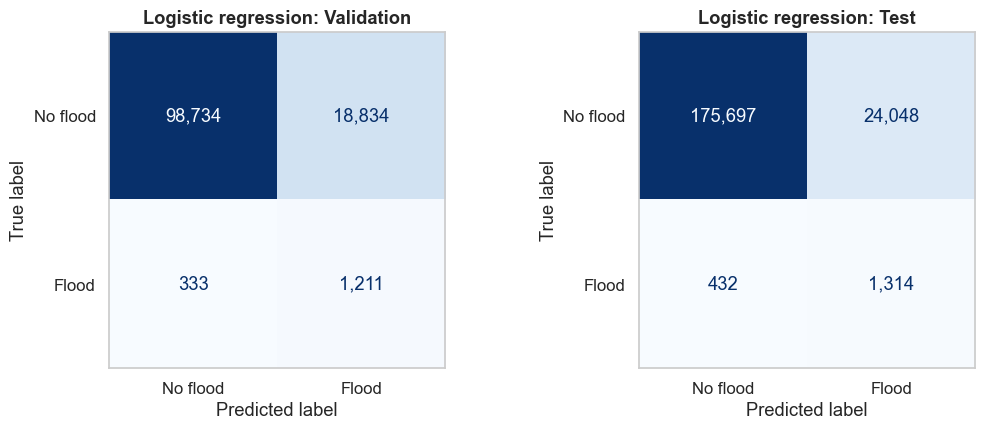

precision  recall     f1      TN  \
model                            data                                           
Logistic regression              Validation      0.060   0.784  0.112   98734   
                                 Test            0.052   0.753  0.097  175697   
Logistic regression (no weights) Validation      0.497   0.050  0.091  117490   
                                 Test            0.410   0.056  0.099  199604   

                                                FP    FN    TP  
model                            data                           
Logistic regression              Validation  18834   333  1211  
                                 Test        24048   432  1314  
Logistic regression (no weights) Validation     78  1467    77  
                                 Test          141  1648    98

Max_lag0    1.30
Avg_lag2   -0.54
Min_lag0    0.37
Max_lag2    0.34
Avg_lag0   -0.34
dtype: float64

In [17]:
# Adapted from Workshop 6: logistic regression with class weights for imbalanced data
baseline = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=0).fit(X_train, y_train)
plain = LogisticRegression(max_iter=1000, random_state=0).fit(X_train, y_train)

splits = {"Validation": (X_val, y_val), "Test": (X_test, y_test)}
baseline_results = evaluate_on_splits(baseline, splits, "Logistic regression")
plain_results = evaluate_on_splits(plain, splits, "Logistic regression (no weights)", plot=False)
display(pd.concat([baseline_results, plain_results]).round(3))

# Largest coefficients (all features are on the same scale, so they can be compared)
coefs = pd.Series(baseline.coef_[0], index=feature_cols_clf)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5).round(2)

Figure 7 shows the baseline's confusion matrices. It finds 78% of floods on the validation year (1,211 of 1,544) and 75% on the test period, but with a precision of only 0.06 and 0.05 (F1 = 0.11 and 0.10): only about 1 in 17 warnings is a real flood. The results are similar on both sets, so the model is not just fitting the training years.

Without class weights the model almost never predicts a flood (precision 0.50, recall 5%). F1 is about 0.1 in both cases, so the weights mainly move the alarm threshold; this is why we choose the threshold on the validation year below. The largest coefficient is today's maximum level (Max_lag0): the model mainly predicts that a station that is high today stays high tomorrow. (The lag features are strongly correlated, so the smaller coefficients should not be read on their own.)

### Decision tree and random forest

Both are tuned with `GridSearchCV` (three time-ordered folds, F1 score). The grids are small because each fit uses several hundred thousand rows; tree models need no scaling.

Decision tree, best parameters: {'max_depth': 12, 'min_samples_leaf': 50}
Random forest, best parameters: {'max_depth': 20, 'min_samples_leaf': 1}


precision  recall     f1      TN     FP    FN  \
model               data                                                        
Logistic regression Validation      0.060   0.784  0.112   98734  18834   333   
                    Test            0.052   0.753  0.097  175697  24048   432   
Decision tree       Validation      0.054   0.732  0.100   97606  19962   414   
                    Test            0.041   0.659  0.077  172837  26908   596   
Random forest       Validation      0.131   0.408  0.198  113380   4188   914   
                    Test            0.104   0.382  0.163  193986   5759  1079   

                                  TP  
model               data              
Logistic regression Validation  1211  
                    Test        1314  
Decision tree       Validation  1130  
                    Test        1150  
Random forest       Validation   630  
                    Test         667

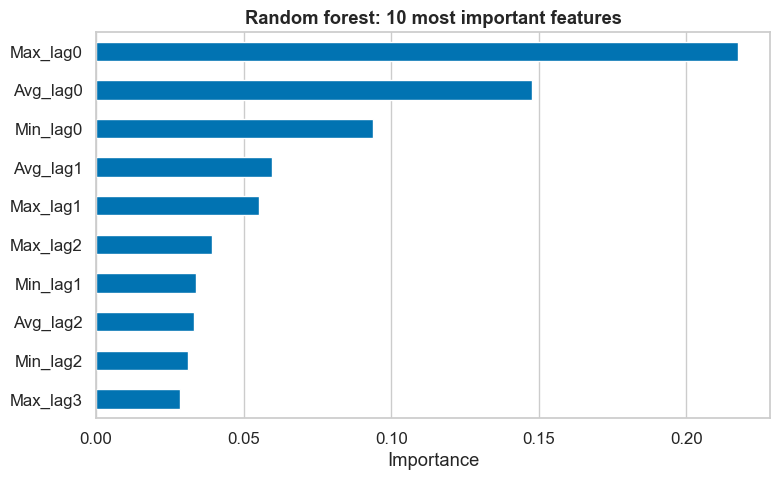

In [18]:
cv_time = TimeSeriesSplit(n_splits=3)

# Decision tree (Workshop 8)
tree_search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=0),
                           {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [50, 500]},
                           cv=cv_time, scoring="f1", n_jobs=-1).fit(X_train, y_train)
tree = tree_search.best_estimator_
print("Decision tree, best parameters:", tree_search.best_params_)

# Random forest (Workshop 8, Ex 10-11)
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=0),
                         {"max_depth": [10, 20], "min_samples_leaf": [1, 50]},
                         cv=cv_time, scoring="f1", n_jobs=-1).fit(X_train, y_train)
forest = rf_search.best_estimator_
print("Random forest, best parameters:", rf_search.best_params_)

# Scores at the default threshold of 0.5
tree_results = evaluate_on_splits(tree, splits, "Decision tree", plot=False)
rf_results = evaluate_on_splits(forest, splits, "Random forest", plot=False)
display(pd.concat([baseline_results, tree_results, rf_results]).round(3))

# Feature importance of the random forest (Workshop 8, Ex 12) - Figure 8
importance = pd.Series(forest.feature_importances_, index=feature_cols_clf).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
importance.plot.barh(ax=ax)
ax.set(xlabel="Importance", title="Random forest: 10 most important features")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Observation:** The grid search chose a tree of depth 12 and a random forest of depth 20. At the default threshold of 0.5 the tree is slightly worse than the baseline (test F1 = 0.08 against 0.10), while the random forest raises far fewer alarms (test recall 0.38, precision 0.10, F1 = 0.16). This does not make it a better model: its probabilities are spread differently, so 0.5 sits at a different point of the precision-recall trade-off, and a fair comparison needs each model's own threshold (below). Figure 8 shows that today's maximum, average and minimum levels are by far the most important features, in line with the logistic regression coefficients.

### Alarm threshold and final model

The threshold of 0.5 is arbitrary, so following Workshop 6 (Ex 8) we plot each model's precision-recall curve on the validation year (Figure 9, left) and choose the threshold with the highest validation F1. The final model is the one with the highest validation F1; Figure 9 (right) shows its confusion matrix on the test period.

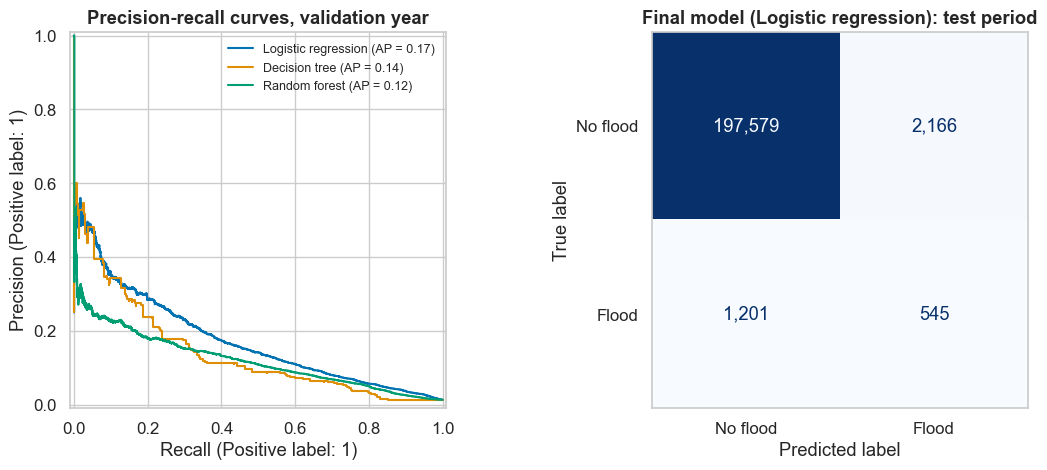

Final model: Logistic regression


threshold  precision  recall     f1      TN  \
model               data                                                      
Logistic regression Validation      0.947      0.236   0.295  0.262  116089   
                    Test            0.947      0.201   0.312  0.245  197579   
Decision tree       Validation      0.939      0.237   0.214  0.225  116504   
                    Test            0.939      0.184   0.195  0.189  198231   
Random forest       Validation      0.653      0.168   0.269  0.207  115504   
                    Test            0.653      0.122   0.243  0.162  196683   

                                  FP    FN   TP  
model               data                         
Logistic regression Validation  1479  1088  456  
                    Test        2166  1201  545  
Decision tree       Validation  1064  1214  330  
                    Test        1514  1405  341  
Random forest       Validation  2064  1128  416  
                    Test        3062  1322  424

In [19]:
models = {"Logistic regression": baseline, "Decision tree": tree, "Random forest": forest}

rows, thresholds = [], {}
fig, (ax_pr, ax_cm) = plt.subplots(1, 2, figsize=(11.5, 4.9))                      # Figure 9
for name, m in models.items():
    prob = m.predict_proba(X_val)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_val, prob, name=name, ax=ax_pr)
    p, r, t = precision_recall_curve(y_val, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    thresholds[name] = t[np.argmax(f1[:-1])]              # threshold with the best F1 on validation
    rows.append(evaluate_on_splits(m, splits, name, threshold=thresholds[name], plot=False))
ax_pr.set_title("Precision-recall curves, validation year")
ax_pr.legend(fontsize=9, loc="upper right")

results = pd.concat(rows)
results.insert(0, "threshold", results.index.get_level_values("model").map(thresholds))

# Final model = highest F1 on the validation year; right panel: its confusion matrix on the test period
best_name = results.xs("Validation", level="data")["f1"].idxmax()
final_test = evaluate_classifier(models[best_name], X_test, y_test, thresholds[best_name])
ConfusionMatrixDisplay(final_test["confusion_matrix"], display_labels=["No flood", "Flood"]).plot(
    ax=ax_cm, values_format=",d", colorbar=False, cmap="Blues")
ax_cm.grid(False)
ax_cm.set_title(f"Final model ({best_name}): test period")
plt.tight_layout(); plt.show()
print("Final model:", best_name)
results.round(3)

**Conclusion.** The logistic regression has the highest precision-recall curve on the validation year (average precision 0.17, against 0.14 for the tree and 0.12 for the random forest) and the highest validation F1 at its chosen threshold (0.26, against 0.23 and 0.21), so it is our **final model** (threshold 0.947). On the unseen test period it finds 545 of the 1,746 flood days (recall 0.31), and about 1 in 5 of its warnings is a real flood (precision 0.20), giving F1 = 0.25 (Figure 9, right): more than twice its F1 at the default threshold (0.10), and above the tree (0.19) and random forest (0.16). The more flexible models do not help, because all of them rely mainly on today's level; choosing the threshold mattered much more than the choice of model.

# Interpretation, Discussion & Conclusions

## Clustering

We grouped the 392 monitoring series into four clusters based on how their water levels behave, rather than on their absolute level or location:

- **Cluster 3, coastal (24):** tidal movements within each day, symmetric levels, weak seasonal cycle.
- **Cluster 1, flashy rivers (147):** rise and fall quickly and recover earliest from the summer low; mostly in the west.
- **Cluster 0, large seasonal rivers (116):** the largest range (about 1 m) and a strong winter-high, summer-low cycle; across Scotland.
- **Cluster 2, slow rivers with rare peaks (105):** the smallest range (about 0.4 m), slow response and occasional sharp rises; mostly in the east.

The groups look meaningful for two reasons: the coastal series form their own group although the coastal flag was not used, and the river clusters show a clear west–east pattern although location was not used. This fits the geography: western catchments are wetter and steeper, so they respond faster to rain.

**Implications for river management.** Flashy western rivers (cluster 1) can rise within a day, so warnings there need short lead times. Slow eastern rivers (cluster 2) are usually quiet but occasionally peak sharply, so long quiet periods should not be read as low flood risk. Coastal gauges (cluster 3) follow tides and storm surges and should be monitored separately.

**Limitations.** The moderate silhouette (about 0.26) means the river groups overlap, so stations near a boundary could belong to either group. Stations also have different recording periods, and only water levels were used.

## Flood classification

**What the model does and how well it works.** The final model, a logistic regression, uses the minimum, average and maximum level of the last seven days to give the chance that tomorrow's maximum level is in the station's highest 1% of days. On the 2025–2026 test period it would have warned of 545 of the 1,746 flood days (about 31%), and about 1 in 5 of its warnings would have been a real flood. The threshold is a trade-off: a lower threshold catches about 75% of floods, but then only about 1 in 19 warnings is real.

**Why it is limited.** The model relies mainly on today's level: water levels show that a river is already high, but not that heavy rain is coming, so floods that start from a normal level are hard to predict. A decision tree and a random forest did not do better.

**Recommendations.**

- Use the model as an early filter that flags stations which are already high, not as a stand-alone warning system.
- Monitor the river types differently (see the clustering above): flashy western rivers give the least warning.

**Limitations.** A flood is defined relative to each station (its highest 1% of days), so it means "unusually high water for this station" rather than confirmed flooding; official flood-warning levels (e.g. from SEPA) would be closer to real floods. The threshold was chosen to maximise F1, whereas in practice it should reflect the cost of a missed flood against a false alarm. The 24 coastal series and 25 short-record stations are not covered.

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

1. MATH11205 Machine Learning in Python, workshop solutions notebooks. University of Edinburgh, 2026: Workshop 1 (EDA and feature engineering), Workshop 3 (k-means, silhouette analysis, hierarchical clustering), Workshop 6 (logistic regression, classification metrics, precision-recall curves, class weights), Workshop 8 (decision trees and random forests).
2. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
3. 1993 Perth flood. Wikipedia. https://en.wikipedia.org/wiki/1993_Perth_flood (accessed November 2026).
4. Scottish Environment Protection Agency (SEPA). Water levels, station 234235. https://waterlevels.sepa.org.uk/Station/234235 (accessed November 2026).
5. Scottish Government. Scotland's Marine Assessment, map 423. https://marine.gov.scot/sma/maps/423 (accessed November 2026).